In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA, SparsePCA, KernelPCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer, PowerTransformer, \
    FunctionTransformer
from sklearn.pipeline import Pipeline
from scipy.stats import boxcox
from sklearn.impute import SimpleImputer

In [72]:
# read in the data from csv file
df = pd.read_csv('data/cleaned data/combined_OESdata.csv')

# Find rows where 'ID 1' contains an underscore
mask = df['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df.loc[mask, ['ID 1', 'Grade']] = df.loc[mask, ['Grade', 'ID 1']].values

# FIXME?: keep lesser and greater?
# Identifying columns that contain 'lesser' or 'greater' in their names
columns_to_drop = [col for col in df.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# FIXME?: keep ID 1 where typ of steel is present for future analysis 
# Adding specific columns to the list
additional_columns = ['Program Name', 'Mode', 'Burn', 'ID 1', 'ID 2', 'ID 3', 'Date']
columns_to_drop.extend(additional_columns)

# Ensuring only columns present in df are attempted to be dropped
columns_to_drop = [col for col in columns_to_drop if col in df.columns]

# Dropping these columns from the DataFrame
df = df.drop(columns=columns_to_drop)

# reduce the number of rows by removing every row without proper grade
df = df[df['Grade'].str.contains('_')]

# Define the condition for moving rows
condition = (df['Fe'] < 97.0) | (df['S'] > 0.09) | (df['Al'] > 0.075) | (df['Pb'] > 0.06)

# Create df_out with rows that match the condition
df_out = df[condition].copy()

# Add the 'Measuring error' column set to True
df_out['Measuring error'] = True

# Remove the rows from the original df
df = df[~condition]
df.describe()

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,...,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000
mean,98.504036,0.187415,0.243858,0.603558,0.024926,0.038063,0.021933,0.004145,0.051400,0.005750,...,0.001655,0.002364,0.040129,0.015414,0.014616,0.001952,0.001273,0.002388,0.039108,0.017430
std,0.439620,0.083674,0.242040,0.158444,0.014630,0.013587,0.039899,0.001657,0.031861,0.008926,...,0.000964,0.001425,0.003745,0.003306,0.009484,0.000515,0.000856,0.000881,0.016881,0.008046
min,97.000000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.005000,0.002000,...,0.001000,0.001000,0.040000,0.015000,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.125000,0.013200,0.493250,0.015025,0.029225,0.007000,0.003000,0.034125,0.002000,...,0.001200,0.001800,0.040000,0.015000,0.007800,0.001600,0.001000,0.002000,0.027500,0.010000
50%,98.500000,0.204000,0.227000,0.601000,0.023000,0.037550,0.012300,0.003400,0.046300,0.002400,...,0.001500,0.002200,0.040000,0.015000,0.013700,0.001900,0.001100,0.002000,0.040750,0.016000
75%,98.800000,0.248000,0.276000,0.694750,0.031475,0.045875,0.023700,0.004800,0.055300,0.004500,...,0.001800,0.002600,0.040000,0.015000,0.018700,0.002200,0.001300,0.002000,0.050400,0.022900
max,99.500000,0.651000,1.420000,1.240000,0.170000,0.089200,0.442000,0.014700,0.287000,0.060900,...,0.017900,0.037100,0.195000,0.058600,0.067700,0.010900,0.010000,0.007100,0.125000,0.095700


In [73]:
# Function to detect outliers in a Series
def find_outliers(series):
    Q1 = series.quantile(0.05)
    Q3 = series.quantile(0.95)
    IQR = Q3 - Q1
    return (series < (Q1 - 1.5 * IQR)) | (series > (Q3 + 1.5 * IQR))

# Apply the function to each column of df, except 'Grade'
outliers = df.drop(columns=['Grade']).apply(find_outliers)

# Any row with at least one outlier in the selected columns
rows_with_outliers = outliers.any(axis=1)

# Select rows containing outliers
new_outliers = df[rows_with_outliers].copy()

# Add the 'outlier' column set to True
new_outliers['outlier'] = True

# Append these rows to the existing df_out
df_out = pd.concat([df_out, new_outliers])

# Remove these rows from the original df
df = df[~rows_with_outliers]

print(new_outliers.describe())
df.describe()

               Fe           C          Si          Mn           P           S  \
count  210.000000  210.000000  210.000000  210.000000  210.000000  210.000000   
mean    98.229048    0.160288    0.347612    0.683076    0.032734    0.040130   
std      0.633864    0.092964    0.317573    0.253896    0.032091    0.016703   
min     97.000000    0.003000    0.005000    0.101000    0.003000    0.002000   
25%     97.800000    0.089200    0.061225    0.507000    0.014800    0.032200   
50%     98.200000    0.163500    0.278000    0.642000    0.022600    0.039700   
75%     98.800000    0.198750    0.503750    0.889000    0.036425    0.049375   
max     99.500000    0.651000    1.420000    1.240000    0.170000    0.089200   

               Cr          Mo          Ni          Al  ...          Ti  \
count  210.000000  210.000000  210.000000  210.000000  ...  210.000000   
mean     0.073683    0.004421    0.062170    0.017388  ...    0.002536   
std      0.125866    0.002306    0.060983    0.0

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,...,2664.000000,2664.000000,2.664000e+03,2.664000e+03,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000
mean,98.525713,0.189553,0.235680,0.597290,0.024310,0.037900,0.017854,0.004124,0.050551,0.004832,...,0.001586,0.002266,4.000000e-02,1.500000e-02,0.014689,0.001941,0.001172,0.002396,0.039367,0.017429
std,0.412965,0.082539,0.233178,0.146585,0.012037,0.013301,0.015693,0.001593,0.028168,0.007118,...,0.000658,0.000604,2.047358e-15,4.250870e-16,0.009596,0.000477,0.000276,0.000888,0.016321,0.007606
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.126000,0.011200,0.492000,0.015100,0.029200,0.007200,0.003000,0.034600,0.002000,...,0.001200,0.001875,4.000000e-02,1.500000e-02,0.007800,0.001600,0.001000,0.002000,0.027900,0.010000
50%,98.500000,0.207000,0.225000,0.599000,0.023000,0.037200,0.012200,0.003400,0.046800,0.002200,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.013600,0.001900,0.001100,0.002000,0.041100,0.016200
75%,98.800000,0.249000,0.270000,0.689000,0.031300,0.045700,0.022900,0.004800,0.055100,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018500,0.002200,0.001200,0.002000,0.050400,0.022800
max,99.500000,0.475000,1.320000,1.040000,0.090000,0.087500,0.110000,0.013700,0.199000,0.055600,...,0.006100,0.005900,4.000000e-02,1.500000e-02,0.067700,0.004200,0.003200,0.007100,0.125000,0.052600


In [74]:
# Remove duplicates
df = df.drop_duplicates()

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,...,2160.000000,2160.000000,2.160000e+03,2.160000e+03,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,98.527685,0.192527,0.231853,0.597188,0.024933,0.038230,0.017751,0.004115,0.049813,0.004606,...,0.001589,0.002275,4.000000e-02,1.500000e-02,0.014517,0.001958,0.001172,0.002398,0.040271,0.017725
std,0.402473,0.080610,0.221696,0.144899,0.012107,0.012990,0.015253,0.001593,0.026715,0.006418,...,0.000659,0.000586,1.068837e-15,3.921383e-16,0.008969,0.000471,0.000277,0.000889,0.015680,0.007679
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.600000,0.025400,0.005000,0.284590,0.005359,0.012318,0.005000,0.003000,0.016159,0.002000,...,0.001000,0.001159,4.000000e-02,1.500000e-02,0.002000,0.001000,0.001000,0.002000,0.004000,0.010000
5%,97.800000,0.043000,0.005000,0.373000,0.008600,0.017995,0.005000,0.003000,0.022500,0.002000,...,0.001000,0.001500,4.000000e-02,1.500000e-02,0.002700,0.001300,0.001000,0.002000,0.013400,0.010000
25%,98.300000,0.132000,0.082450,0.494000,0.015900,0.029800,0.007500,0.003000,0.034600,0.002000,...,0.001200,0.001900,4.000000e-02,1.500000e-02,0.008000,0.001600,0.001000,0.002000,0.029875,0.010000
50%,98.500000,0.210000,0.225000,0.596000,0.023400,0.037600,0.012400,0.003400,0.046200,0.002300,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.014000,0.001900,0.001100,0.002000,0.041900,0.016700
75%,98.800000,0.250000,0.270000,0.690250,0.031800,0.045800,0.022625,0.004800,0.054925,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018400,0.002200,0.001200,0.002000,0.050800,0.023100
95%,99.200000,0.304000,0.844000,0.841000,0.046600,0.061500,0.051000,0.007000,0.108050,0.017205,...,0.003100,0.003300,4.000000e-02,1.500000e-02,0.030705,0.002800,0.001700,0.004600,0.064000,0.030905


In [75]:
# TODO: find measuring errors and remove them
# FIXME?: remove rows with 'nan' or 0 values in column 'Grade'
# FIXME?: don't group by grade and take the mean
# merge the rows with the same grade
df = df.groupby('Grade').mean()

# reset the index
df = df.reset_index()

# Drop the 'Grade' column
df = df.drop(columns=['Grade'])

df_out = df_out.reset_index()
df_out = df_out.drop(columns=['index'])

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,...,407.000000,407.000000,4.070000e+02,4.070000e+02,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000
mean,98.528358,0.195502,0.235124,0.594342,0.024793,0.038842,0.016987,0.004119,0.049039,0.004819,...,0.001624,0.002267,4.000000e-02,1.500000e-02,0.014305,0.001957,0.001178,0.002397,0.039841,0.017518
std,0.401253,0.081389,0.221227,0.147132,0.012246,0.012922,0.014826,0.001587,0.026267,0.006438,...,0.000686,0.000598,4.168460e-16,8.339939e-17,0.008871,0.000437,0.000271,0.000646,0.015674,0.006822
min,97.300000,0.003933,0.005000,0.055800,0.003000,0.002000,0.005000,0.003000,0.011583,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.562400,0.019077,0.005000,0.266160,0.005357,0.004694,0.005000,0.003000,0.015918,0.002000,...,0.001000,0.001162,4.000000e-02,1.500000e-02,0.002000,0.001068,0.000060,0.002000,0.000240,0.000600
5%,97.800000,0.042159,0.005000,0.366933,0.008457,0.018400,0.005000,0.003000,0.021965,0.002000,...,0.001017,0.001524,4.000000e-02,1.500000e-02,0.002677,0.001288,0.001000,0.002000,0.012692,0.010000
25%,98.300000,0.136417,0.104417,0.494750,0.015875,0.030842,0.006992,0.003017,0.033775,0.002000,...,0.001200,0.001854,4.000000e-02,1.500000e-02,0.007775,0.001667,0.001017,0.002000,0.029192,0.011350
50%,98.483333,0.213333,0.226667,0.588500,0.023317,0.038617,0.012000,0.003600,0.045350,0.002640,...,0.001450,0.002167,4.000000e-02,1.500000e-02,0.013650,0.001933,0.001100,0.002017,0.041500,0.017000
75%,98.708333,0.252750,0.272583,0.692694,0.031233,0.047225,0.021125,0.004567,0.054875,0.004275,...,0.001733,0.002583,4.000000e-02,1.500000e-02,0.018117,0.002217,0.001250,0.002542,0.050900,0.021717
95%,99.200000,0.309400,0.843900,0.843933,0.046963,0.060663,0.048157,0.006747,0.092439,0.017362,...,0.003207,0.003245,4.000000e-02,1.500000e-02,0.030215,0.002785,0.001667,0.003731,0.063535,0.028872


# PCA

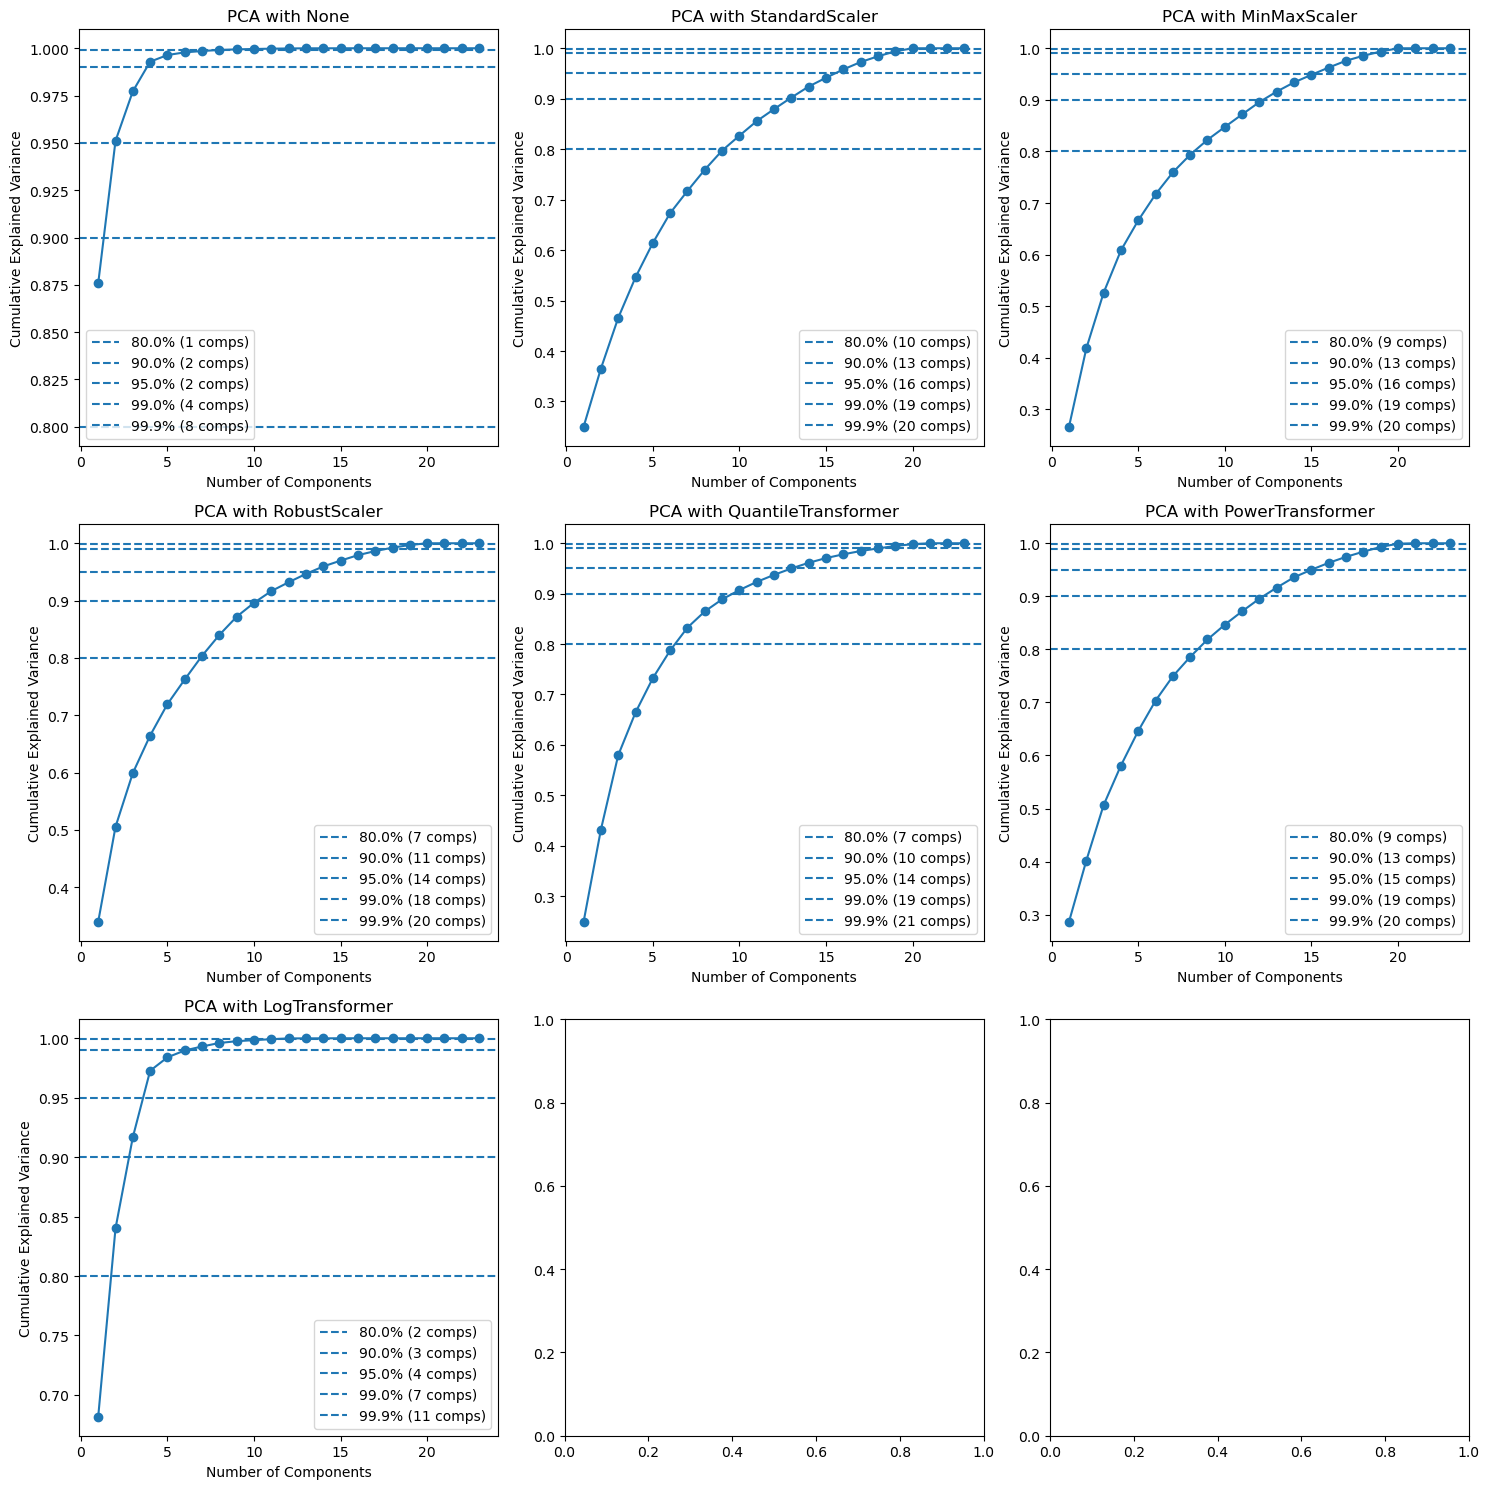

In [76]:
# Define scalers
scalers = {
    'None': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'QuantileTransformer': QuantileTransformer(n_quantiles=len(df), output_distribution='normal'),
    'PowerTransformer': PowerTransformer(),
    'LogTransformer': FunctionTransformer(np.log1p, validate=True)
}

# Placeholder for results
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15))
axes = axes.flatten()

for i, (scaler_name, scaler) in enumerate(scalers.items()):
    # Create pipeline
    pipeline = Pipeline([
        ('scaler', scaler),
        ('pca', PCA())
    ]) if scaler is not None else Pipeline([('pca', PCA())])
    
    # Fit and transform data
    pipeline.fit(df)
    exp_var_ratio = np.cumsum(pipeline.named_steps['pca'].explained_variance_ratio_)
    
    # Plotting
    axes[i].plot(range(1, len(exp_var_ratio) + 1), exp_var_ratio, marker='o')
    axes[i].set_title(f'PCA with {scaler_name}')
    axes[i].set_xlabel('Number of Components')
    axes[i].set_ylabel('Cumulative Explained Variance')
    
    # Add horizontal lines for thresholds
    for threshold in [0.8, 0.9, 0.95, 0.99, 0.999]:
        n_components = np.argmax(exp_var_ratio >= threshold) + 1
        axes[i].axhline(y=threshold, linestyle='--', label=f'{threshold*100}% ({n_components} comps)')
        axes[i].legend()

plt.tight_layout()
plt.show()

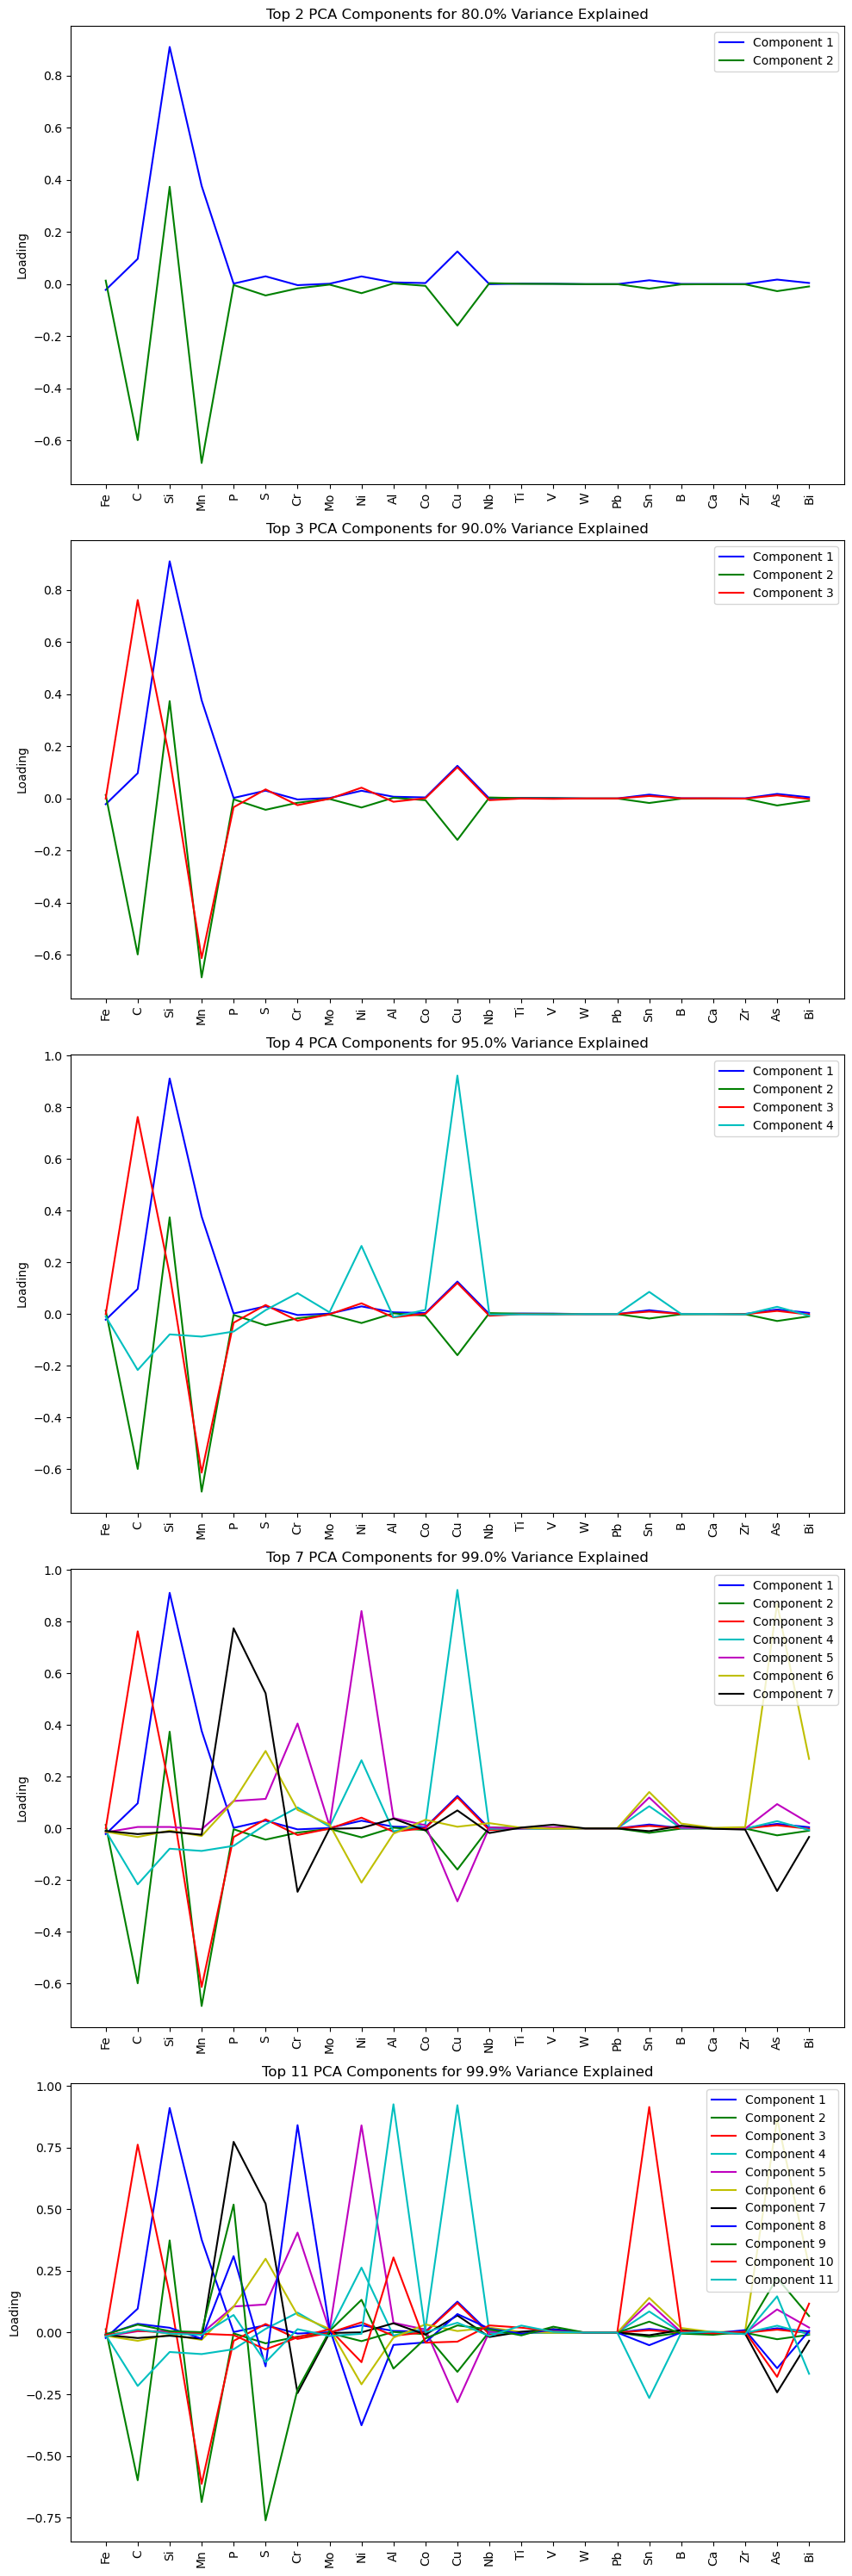

In [77]:
# Standardizing the Data using log1p transformation
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Fitting PCA
pca = PCA()
pca.fit(df_scaled)

# Calculating cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Finding the number of components for different levels of explained variance
thresholds = [0.80, 0.90, 0.95, 0.99, 0.999]
n_components = [np.argmax(cumulative_variance >= t) + 1 for t in thresholds]

# Plotting
fig, ax = plt.subplots(len(thresholds), 1, figsize=(10, 6 * len(thresholds)))

# Colors for different components
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k']

for i, t in enumerate(thresholds):
    num_components = n_components[i]
    pca_components = pca.components_[:num_components]

    # Plotting the relative importance of features for each component
    for j in range(num_components):
        ax[i].plot(df.columns, pca_components[j, :], label=f'Component {j+1}', color=colors[j % len(colors)])

    ax[i].set_title(f'Top {num_components} PCA Components for {t*100}% Variance Explained')
    ax[i].set_xticks(range(len(df.columns)))
    ax[i].set_xticklabels(df.columns, rotation=90)
    ax[i].set_ylabel('Loading')
    ax[i].legend()

plt.tight_layout()
plt.show()

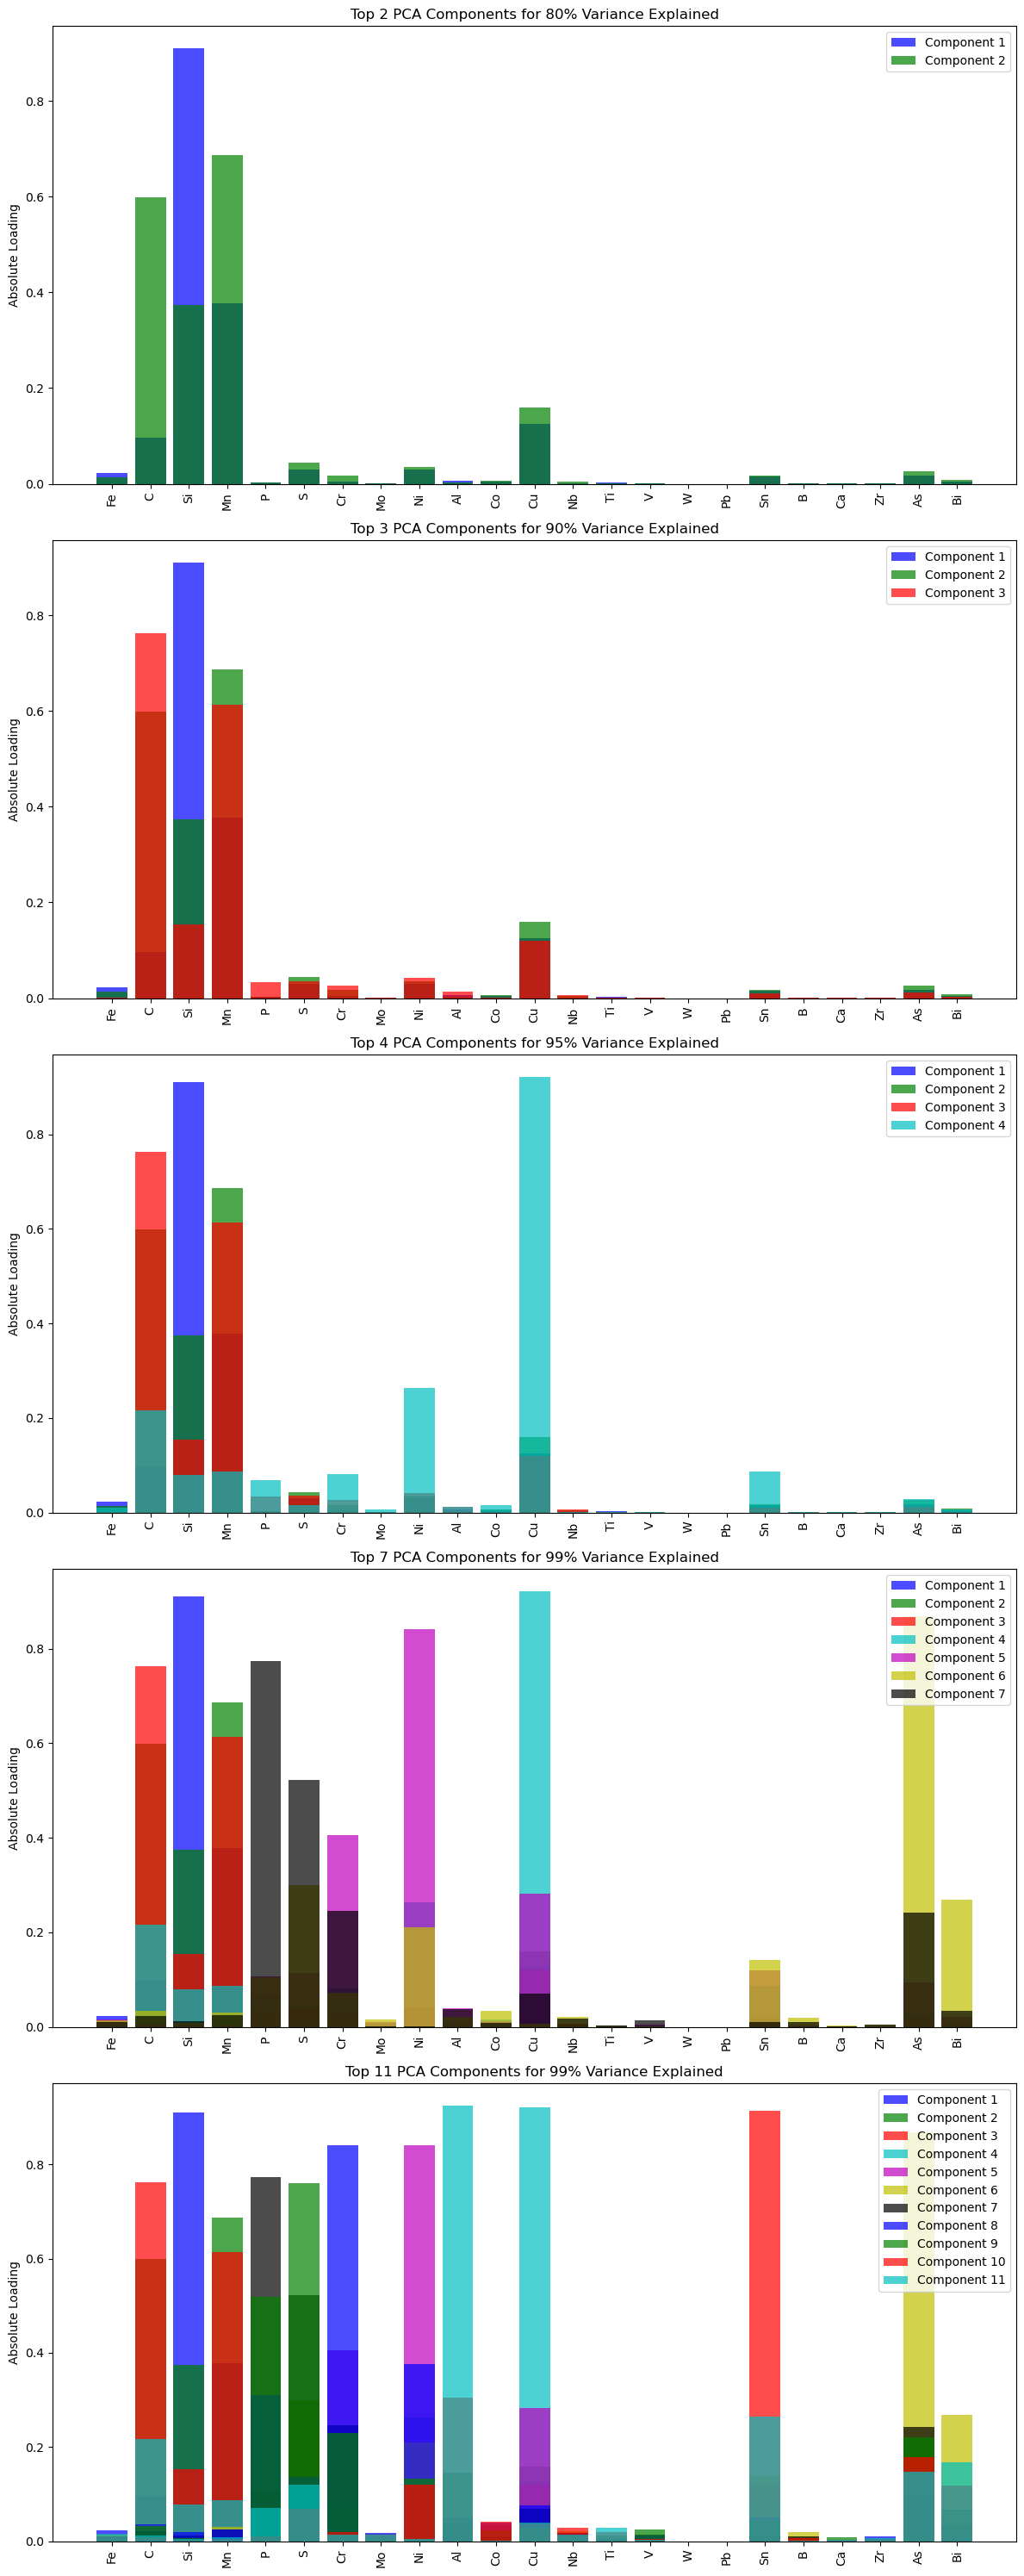

In [78]:
# Standardizing the Data using log1p transformation
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Fitting PCA
pca = PCA()
pca.fit(df_scaled)

# Calculating cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Finding the number of components for different levels of explained variance
thresholds = [0.80, 0.90, 0.95, 0.99, 0.999]
n_components = [np.argmax(cumulative_variance >= t) + 1 for t in thresholds]

# Plotting
fig, ax = plt.subplots(len(thresholds), 1, figsize=(12, 6 * len(thresholds)))

# Colors for different components
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k']

for i, t in enumerate(thresholds):
    num_components = n_components[i]
    pca_components = pca.components_[:num_components]

    # Bar chart for each PCA component's absolute loadings
    for j in range(num_components):
        ax[i].bar(df.columns, np.abs(pca_components[j, :]), label=f'Component {j+1}', color=colors[j % len(colors)], alpha=0.7)

    ax[i].set_title(f'Top {num_components} PCA Components for {int(t*100)}% Variance Explained')
    ax[i].set_xticks(range(len(df.columns)))
    ax[i].set_xticklabels(df.columns, rotation=90)
    ax[i].set_ylabel('Absolute Loading')
    ax[i].legend()

plt.tight_layout()
plt.show()